# Explaining the network with exact Shapley values

**Explanation notebook 1 in `notebooks/xai/`.** `notebooks/README.md` says how every notebook is laid out and who it is written for. `notebooks/xai/README.md` says what every explanation notebook shares — the same trained network, the same engine, the same stand-in for a removed sensor — and why.

## What this notebook is for

Notebook 02 trained a network that reads 14 sensors' last 30 flight cycles and predicts how many cycles of life the engine has left. This notebook takes one of those predictions at a time and divides it among the 14 sensors, using the method Wen et al. (2026) use: the **Shapley value**. It then repeats the division at every cycle of one engine's life and draws the result, so you can see which sensors the prediction leaned on while the engine was healthy, and which it leaned on as the engine wore out.

## What it does not do

- **It does not train anything.** It loads a network that `scripts/train.py` trained and stored with the commit of the code that trained it.
- **It does not say what wears an engine.** A Shapley value describes how this network used its inputs. Section 6 lists what else it does not show.
- **Its numbers are not the paper's Table 12.** That table has the same layout — sensors down the side, moments in one engine's life across the top — but it cannot hold signed Shapley values that add up the way the paper's own Equation 14 requires (finding F-08). The two are never set side by side as the same quantity.

## The notebook in one list

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 1 | **Load** the trained network | a stored five-seed run | seed 42's network, and the data rebuilt as that network saw it |
| 2 | **Choose** what removing a sensor means | the training windows | one stand-in window, and the network's prediction for it |
| 3 | **Work three sensors by hand** | one window, three sensors | all 6 orders they could join in, and their 3 Shapley values |
| 4 | **Compute all fourteen**, exactly | the same window | 14 Shapley values that add up to the prediction minus the stand-in's |
| 5 | **Follow one engine's life** | every window of one held-back engine | 14 values at every cycle, drawn as 14 small charts |
| 6 | **Rank the sensors**, overall and by stage of life | those values | which sensors mattered, and how that changed as the engine wore |
| 7 | **Check the other four networks** | the run's 5 networks and the 100 test engines | one ranking per network, and how closely they agree |

## 1. Background

### What exactly is being explained

One **prediction**. The network receives one example, an array of shape `(14, 30)` — 14 sensors, each with its readings over the 30 most recent flight cycles — and returns one number: the predicted remaining life, in flight cycles. The question is how much of that number each of the 14 sensors is responsible for.

### Why that question has no obvious answer

If the network added up fourteen separate terms, one per sensor, each term would be that sensor's share and there would be nothing to discuss. It does not. Its graph layers mix every sensor with the sensors it is joined to, and after each layer every negative number is set to zero, so how far one sensor moves the prediction depends on what the other sensors are reading.

A made-up function of two inputs shows the difficulty:

```
f(a, b) = 2a + 3b + 4ab
```

Compare the input `a = 1, b = 1` with a reference input `a = 0, b = 0`. The whole change to explain is `f(1, 1) − f(0, 0) = 9 − 0 = 9`. How much of the 9 belongs to `a`?

- Switch `a` on first, with `b` still at 0: `f(1, 0) − f(0, 0) = 2 − 0 = 2`. Then switch `b` on: `f(1, 1) − f(1, 0) = 9 − 2 = 7`.
- Switch `b` on first: `f(0, 1) − f(0, 0) = 3 − 0 = 3`. Then switch `a` on: `f(1, 1) − f(0, 1) = 9 − 3 = 6`.

`a` adds 2 or 6 depending on whether `b` is already there. The reason is the `4ab` term, an **interaction**: a part of the output that neither input produces on its own. Neither 2 nor 6 is wrong. Each is the right answer for one order of arrival.

### The Shapley value: average over every order

The **Shapley value** (Shapley, 1953) settles the question by averaging each player's contribution over every order in which the players could arrive. It comes from cooperative game theory, the mathematics of how a group that produced something together should divide the credit. Here the players are sensors, and what they produced together is the prediction.

In the example, `a`'s Shapley value is `(2 + 6) / 2 = 4` and `b`'s is `(7 + 3) / 2 = 5`. They add up to 9, the whole change, and the interaction's 4 has been split evenly between the two inputs that make it. The adding up is not luck. In each order, the amounts added along the way sum to the change from nothing switched on to everything switched on — that is simply how the steps were defined — so the averages over the orders sum to it too. This property is called **efficiency**, and step 4 checks it.

### What "switching a sensor off" means for a network

In the example, "off" meant 0. A network built for fourteen sensors cannot be run with thirteen, so a sensor is never really removed. Its 30 readings are **replaced** by a stand-in. This notebook's stand-in is that sensor's average window over the training engines: "this sensor is behaving typically" (assumption A-20). Step 2 builds it. The prediction for a window made entirely of stand-ins is the **reference prediction**. It plays the part of "nothing switched on" in the example, and every Shapley value below is measured from it.

**Do not confuse** a Shapley value with an attention weight or a gradient. A Shapley value is obtained by changing the inputs and running the network again, it is in the unit of the prediction (here, cycles), and the fourteen values of one window add up to a real difference between two predictions. The network's parameters are never read.

## 2. Setup

The first cell imports what the notebook uses and makes the package importable from a clone that has not been installed. The second finds the stored run to explain: the most recent five-seed run of `config/fd001.yaml` with the paper's sensor graph, the last-cycle temporal stage, the network sizes of the paper's Table 4 and the step learning-rate schedule, whose trained networks were saved. If there is none, it stops and prints the command that makes one.

In [1]:
from __future__ import annotations

import logging
import sys
import time
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from scipy import stats

# The project's top folder is the nearest one above this notebook that holds
# pyproject.toml. Adding its src/ folder to Python's search path makes the
# package importable from a clone that was never installed.
PROJECT_ROOT = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook runs a trained network, which needs PyTorch, and PyTorch is "
        'not installed. Install the project with  pip install -e ".[model]"'
    ) from missing

from thesis_gnn_rul_xai.config import load_config
from thesis_gnn_rul_xai.docsite.figures import render_figure
from thesis_gnn_rul_xai.explain import (
    coalition_weights,
    dynamic_shap,
    efficiency_error,
    mean_window_baseline,
    plot_contributions_over_time,
    shap_summary,
    shap_values,
)
from thesis_gnn_rul_xai.models import ModelConfig
from thesis_gnn_rul_xai.training import evaluate_model, find_runs, load_seed
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.ERROR)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"Python      : {sys.version.split()[0]}")
print(f"PyTorch     : {torch.__version__}")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
Python      : 3.11.9
PyTorch     : 2.13.0+cpu


In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")
runs = [
    run for run in find_runs(
        preprocessing=config, seeds=5, with_weights=True, split="varies_with_seed",
        early_stopping=True, lr_schedule="step", temporal_stage="last_cycle",
    )
    if run.model_config == ModelConfig()
]
if not runs:
    raise FileNotFoundError(
        "reports/ holds no five-seed run of config/fd001.yaml that saved its trained "
        "networks. Make one, which takes a few minutes on a processor, with\n\n"
        "    python scripts/train.py --config config/fd001.yaml --seeds 5\n\n"
        "and run this notebook again."
    )
run = runs[-1]
SEED = 42

print(f"Stored run : {run.name}")
print(f"Commit     : {run.summary['commit']}")
print(f"Finished   : {run.summary['finished_utc']} (UTC)")
print(f"Seeds      : {run.seeds}. Steps 1 to 6 explain seed {SEED}; step 7 checks all five.")

Stored run : fd001_physics_row_cap_5seed_varsplit_cfgba82e3_5602773-dirty_20260914T233911Z
Commit     : 5602773-dirty
Finished   : 20260914T233911Z (UTC)
Seeds      : [42, 43, 44, 45, 46]. Steps 1 to 6 explain seed 42; step 7 checks all five.


## 3. The trained network

### Step 1 — Load the trained network

**What.** Load the parameters seed 42's network ended its training with, and rebuild the data it was trained on from the settings stored beside them.

**Why.** An explanation has to be an explanation of something definite. Loading the stored network, rather than training one here, means the network explained is the one whose test error is part of the reported five-seed result, and the same one every other notebook in `xai/` explains. The data has to be rebuilt with the same seed, because the seed decided which 20 training engines were held back: rebuilding with another seed would call engines "unseen" that this network learned from.

In [3]:
model, prepared = load_seed(run, SEED)
sensors = list(prepared.sensor_symbols)

print(f"Network: {model.count_parameters():,} parameters; sensor nodes {', '.join(sensors)}")
print(f"Data   : {len(prepared.train):,} training windows, "
      f"{len(prepared.validation):,} held-back windows, {len(prepared.test)} test windows")
print(f"One example has shape {prepared.test.features.shape[1:]}: 14 sensors, 30 cycles each.")

Network: 61,729 parameters; sensor nodes T24, T30, T50, P15, P30, Nf, Nc, Ps30, phi, NRf, BPR, htBleed, W31, W32
Data   : 14,459 training windows, 3,272 held-back windows, 100 test windows
One example has shape (14, 30): 14 sensors, 30 cycles each.


**Check.** If the loaded network is the stored one, and the data is the data it saw, then scoring the 100 test engines again must give exactly the error the run recorded for seed 42.

In [4]:
recorded = run.results.set_index("seed").loc[SEED]
scored = evaluate_model(model, prepared.test)
print(f"test RMSE, scored now        {scored['rmse']:.6f} cycles")
print(f"test RMSE, recorded by run   {recorded['rmse']:.6f} cycles")

same_network = bool(np.isclose(scored["rmse"], recorded["rmse"], rtol=0, atol=1e-6))
assert same_network, "The loaded network does not score what the stored run recorded."
print("\nOK  The network explained below is the one the stored run trained.")

test RMSE, scored now        16.694915 cycles
test RMSE, recorded by run   16.694915 cycles

OK  The network explained below is the one the stored run trained.


## 4. The explanation, step by step

### Step 2 — The stand-in for a removed sensor

**What.** Average every training window, sensor by sensor and cycle by cycle, into one window of shape `(14, 30)`, and run the network on it.

**Why.** Equation 15 of the paper needs a prediction "when only sensors in subset S are considered", and the paper never says what the network is given in place of the others. This notebook gives it each missing sensor's average training window (assumption A-20). Only training windows go into the average, so no held-back or test engine shapes the explanation, for the same reason none of them shapes the rescaling.

Notebook 01 rescaled every sensor to count how many spreads (standard deviations) a reading sits from that sensor's training average. So the stand-in should be close to zero everywhere: the average window is, almost, "every reading exactly average". It is not exactly zero, because windows count the middle cycles of an engine's life more often than its first and last ones.

In [5]:
baseline = mean_window_baseline(prepared.train)
with torch.no_grad():
    reference = float(model.predict_cycles(torch.from_numpy(baseline[None]))[0])

print(f"stand-in window: shape {baseline.shape}, averaged over {len(prepared.train):,} training windows")
print(f"its entry furthest from zero: {np.abs(baseline).max():.3f} spreads")
print(f"reference prediction, for a window made entirely of stand-ins: {reference:.3f} cycles")

stand-in window: shape (14, 30), averaged over 14,459 training windows
its entry furthest from zero: 0.274 spreads
reference prediction, for a window made entirely of stand-ins: 91.885 cycles


**Check.** The reference prediction is a prediction like any other, so it must lie between 0 and the ceiling of 125 cycles, the most this network's last layer can produce.

In [6]:
reference_in_range = 0.0 <= reference <= config.rul_max
assert reference_in_range
print(f"OK  0 <= {reference:.3f} <= {config.rul_max}")

OK  0 <= 91.885 <= 125


### Step 3 — Three sensors, worked by hand

**What.** Take one real window: the last window of the held-back engine that step 5 follows, a moment close to its failure. Pick three sensors, `Nc`, `T30` and `P15`. Keep the other eleven at their real readings the whole time, and treat the three as the only players. With three players there are 2 × 2 × 2 = 8 groups of them that could be switched on, and 3 × 2 × 1 = 6 orders in which they could arrive. That is few enough to list every one.

**Why.** Equation 15 is this same calculation with fourteen players. With three, every number can be checked by eye. This is a smaller game than the one step 4 plays — eleven sensors are never switched off here — so these three values are not what the same sensors receive in step 4. They show how the calculation works, not what the sensors are worth.

The engine is chosen once, here, and used again in step 5: the held-back engine with the most windows. It is one the network never learned from, and it has the longest recorded life of the held-back engines, so it shows the most of an engine's wear.

The figure lists every order three players, A, B and C, could arrive in. B's Shapley value is what B adds on arriving, averaged over all six rows.

In [7]:
display(HTML(render_figure("shapley")))

In [8]:
held_back = prepared.validation
units, counts = np.unique(held_back.units, return_counts=True)
engine = int(units[np.argmax(counts)])
engine_rows = np.flatnonzero(held_back.units == engine)
engine_rows = engine_rows[np.argsort(held_back.end_cycles[engine_rows])]

last = engine_rows[-1]
window = held_back.features[last]
players = ["Nc", "T30", "P15"]
position = {sensor: sensors.index(sensor) for sensor in players}


def prediction_with(switched_on) -> float:
    """The prediction when only these players keep their real readings."""
    example = window.copy()
    for sensor in players:
        if sensor not in switched_on:
            example[position[sensor]] = baseline[position[sensor]]
    with torch.no_grad():
        return float(model.predict_cycles(torch.from_numpy(example[None]))[0])


groups = [(), ("Nc",), ("T30",), ("P15",), ("Nc", "T30"), ("Nc", "P15"),
          ("T30", "P15"), ("Nc", "T30", "P15")]
value = {frozenset(group): prediction_with(group) for group in groups}

print(f"Engine {engine}: {len(engine_rows)} windows. The one used here ends at cycle "
      f"{held_back.end_cycles[last]}, with {held_back.targets[last]:.0f} cycles truly left.")
print(f"The network predicts {value[frozenset(players)]:.3f} cycles for it.\n")
display(pd.DataFrame({
    "switched on": [", ".join(group) or "none of the three" for group in groups],
    "prediction (cycles)": [value[frozenset(group)] for group in groups],
}).round(3))

Engine 5: 240 windows. The one used here ends at cycle 269, with 0 cycles truly left.
The network predicts 4.596 cycles for it.



,switched on,prediction (cycles)
0,none of the three,17.835
1,Nc,9.229
2,T30,10.034
3,P15,17.135
4,"Nc, T30",4.838
5,"Nc, P15",8.819
6,"T30, P15",9.738
7,"Nc, T30, P15",4.596


The table is everything the calculation needs: eight predictions. The first row, none of the three switched on, is not the reference prediction of step 2, because the other eleven sensors keep their real readings in this smaller game.

The next cell goes through the six orders. Along each order it records what each sensor adds on arriving: the prediction after it joins, minus the prediction before. The column averages are the Shapley values of this three-sensor game.

In [9]:
records = []
for order in permutations(players):
    switched_on, added = [], {}
    for sensor in order:
        before = value[frozenset(switched_on)]
        switched_on.append(sensor)
        added[sensor] = value[frozenset(switched_on)] - before
    records.append({"order of arrival": " then ".join(order),
                    **{f"{sensor} adds": added[sensor] for sensor in players}})

orders = pd.DataFrame(records)
display(orders.round(3))

by_orders = {sensor: float(orders[f"{sensor} adds"].mean()) for sensor in players}
total_change = value[frozenset(players)] - value[frozenset()]
print("Averaged over the six orders:")
for sensor in players:
    print(f"  {sensor:4s} {by_orders[sensor]:+9.3f} cycles")
print(f"  sum  {sum(by_orders.values()):+9.3f}")
print(f"\nprediction with all three  minus  prediction with none: {total_change:+9.3f}")

,order of arrival,Nc adds,T30 adds,P15 adds
0,Nc then T30 then P15,-8.606,-4.391,-0.242
1,Nc then P15 then T30,-8.606,-4.223,-0.410
2,T30 then Nc then P15,-5.196,-7.801,-0.242
3,T30 then P15 then Nc,-5.143,-7.801,-0.296
4,P15 then Nc then T30,-8.316,-4.223,-0.700
5,P15 then T30 then Nc,-5.143,-7.397,-0.700


Averaged over the six orders:
  Nc      -6.835 cycles
  T30     -5.973 cycles
  P15     -0.432 cycles
  sum    -13.239

prediction with all three  minus  prediction with none:   -13.239


Look down `Nc`'s column. When `Nc` arrives first it moves the prediction by −8.606 cycles; when it arrives after `T30` it moves it by only −5.196. Once `T30` has already pulled the prediction down, `Nc` has less left to add: the two sensors partly tell the network the same thing about this engine. That is an interaction, like the `4ab` term of section 1, and it is why no single row can be called `Nc`'s contribution. The Shapley value, −6.835, is the average of all six.

**Check.** Efficiency: the three values must add up to the whole change, the prediction with all three switched on minus the prediction with none.

The same numbers can also be reached without listing orders, and that is the form Equation 15 uses. Count the orders in which `Nc` arrives to find exactly a given group already there. `Nc` arrives first, finding nobody, in 2 of the 6 orders (a share of 1/3). It arrives second, after `T30` alone, in 1 of the 6 (1/6), and likewise after `P15` alone (1/6). It arrives last, finding both, in 2 of the 6 (1/3). So `Nc`'s value is those four shares multiplied by what `Nc` adds to each group, summed. `coalition_weights(3)` returns the shares by group size, 1/3, 1/6 and 1/3, and the cell checks that the two routes agree.

In [10]:
three_add_up = abs(sum(by_orders.values()) - total_change) < 1e-6
assert three_add_up
print(f"OK  {sum(by_orders.values()):+.6f} = {total_change:+.6f}")

weights = coalition_weights(3)
print(f"\nShares by group size, from coalition_weights(3): {np.round(weights, 4).tolist()}")
by_groups = {
    sensor: sum(
        weights[len(group)] * (value[frozenset(group) | {sensor}] - value[frozenset(group)])
        for group in groups if sensor not in group
    )
    for sensor in players
}
routes_agree = all(abs(by_groups[s] - by_orders[s]) < 1e-6 for s in players)
assert routes_agree
for sensor in players:
    print(f"  {sensor:4s} by orders {by_orders[sensor]:+9.3f}   by groups {by_groups[sensor]:+9.3f}")
print("OK  Averaging over orders and weighting groups give the same values.")

OK  -13.239467 = -13.239467

Shares by group size, from coalition_weights(3): [0.3333, 0.1667, 0.3333]
  Nc   by orders    -6.835   by groups    -6.835
  T30  by orders    -5.973   by groups    -5.973
  P15  by orders    -0.432   by groups    -0.432
OK  Averaging over orders and weighting groups give the same values.


### Step 4 — All fourteen sensors, exactly

**What.** The same window, now with every sensor a player. This is the paper's Equation 15:

$$\phi_i \;=\; \sum_{S \,\subseteq\, N \setminus \{i\}} \frac{|S|!\,(n-|S|-1)!}{n!}\,\Big(f(S \cup \{i\}) - f(S)\Big)$$

- $n = 14$, the number of sensors, and $N$ is the set of all fourteen.
- $i$ is the sensor being credited, and $\phi_i$ its Shapley value, in cycles.
- $S$ is a group of the other sensors — any group, from none of them to all thirteen — and $|S|$ is how many sensors it holds.
- $f(S)$ is the prediction when the sensors in $S$ keep their real readings and every other sensor is replaced by its stand-in.
- $f(S \cup \{i\}) - f(S)$ is what sensor $i$ adds to the group $S$ — one entry of step 3's order table.
- The fraction is the share of all $n!$ orders in which exactly the sensors of $S$ arrive before $i$: the same count step 3 did by hand for three sensors, where it gave 1/3, 1/6 and 1/3.

The whole sum is step 3's average over every order, computed group by group instead of order by order.

**Why it can be exact here.** Fourteen sensors can arrive in 14! = 87,178,291,200 orders, but those orders only ever pass through 2¹⁴ = 16,384 distinct groups, and each group needs one run of the network. `shap_values` runs the network on all 16,384 versions of the window and applies the weights. Most software for Shapley values has to sample orders instead, because with many more inputs the groups cannot all be listed. Nothing is sampled here, so a disagreement with the paper can never be blamed on sampling noise.

In [11]:
phi = shap_values(model, window, baseline)
with torch.no_grad():
    predicted = float(model.predict_cycles(torch.from_numpy(window[None]))[0])

table = pd.DataFrame({"sensor": sensors, "Shapley value (cycles)": phi})
table = table.reindex(table["Shapley value (cycles)"].abs().sort_values(ascending=False).index)
display(table.round(3).reset_index(drop=True))

print(f"prediction                          {predicted:9.3f} cycles")
print(f"reference prediction                {reference:9.3f}")
print(f"sum of the 14 Shapley values        {phi.sum():+9.3f}")
print(f"prediction minus reference          {predicted - reference:+9.3f}")
print()
for sensor in players:
    print(f"{sensor:4s} in the three-sensor game {by_orders[sensor]:+8.3f}   among all fourteen {phi[position[sensor]]:+8.3f}")

,sensor,Shapley value (cycles)
0,Nc,-24.898
1,T24,-16.862
2,T50,-16.345
3,htBleed,-14.414
4,T30,-12.864
5,Ps30,-11.171
6,BPR,-10.120
7,W31,9.982
8,P30,7.455
9,W32,4.779


prediction                              4.596 cycles
reference prediction                   91.885
sum of the 14 Shapley values          -87.290
prediction minus reference            -87.290

Nc   in the three-sensor game   -6.835   among all fourteen  -24.898
T30  in the three-sensor game   -5.973   among all fourteen  -12.864
P15  in the three-sensor game   -0.432   among all fourteen   -0.677


The last three lines show why step 3's values were only an illustration. In the three-sensor game the other eleven sensors were always at their real readings. Among all fourteen, each sensor's contribution is averaged over groups in which those eleven are often replaced by stand-ins, and because of interactions that changes what it adds.

**Check.** Efficiency, which is the paper's Equation 14. The paper writes that equation with a constant it calls the average value of the target variable across all samples. The only constant these values can add up to is the reference prediction, so that is what they are measured from (assumption A-24). If the sum missed by more than rounding, the numbers would not be Shapley values however sensible they looked.

In [12]:
window_error = efficiency_error(model, window, baseline, phi)
fourteen_add_up = window_error < 1e-4
assert fourteen_add_up
print(f"OK  The 14 values miss (prediction minus reference) by {window_error:.1e} cycles.")

OK  The 14 values miss (prediction minus reference) by 9.5e-07 cycles.


### Step 5 — Every cycle of one engine's life

**What.** Step 4, repeated at every window of the engine chosen in step 3: the window ending at cycle 30, the one ending at cycle 31, and so on to the engine's last recorded cycle. This is the paper's Equation 16, which is Equation 15 applied at each time step.

**Why.** One prediction shows what the network leaned on at one moment. The paper's claim — and the reason its title calls its explanation *dynamic* — is that what matters changes as an engine degrades. Following one engine through its whole life shows that directly. A held-back engine is used because the network never learned from it; a test engine cannot be, because the test set keeps only one window per engine.

In [13]:
started = time.perf_counter()
attribution = dynamic_shap(model, held_back, baseline, unit=engine, symbols=sensors)
seconds = time.perf_counter() - started

print(f"Engine {engine}: {len(attribution)} windows x {2**14:,} groups = "
      f"{len(attribution) * 2**14:,} runs of the network, in {seconds:.1f} s.")
display(attribution.head(3).round(2))

Engine 5: 240 windows x 16,384 groups = 3,932,160 runs of the network, in 14.3 s.


,end_cycle,rul,predicted,baseline,T24,T30,T50,P15,P30,Nf,Nc,Ps30,phi,NRf,BPR,htBleed,W31,W32
0,30,125.0,121.629997,91.89,2.91,14.06,7.33,10.70,-9.24,3.44,0.53,6.1,-9.48,2.94,2.94,7.99,-4.35,-6.13
1,31,125.0,120.150002,91.89,7.08,13.24,6.48,6.43,-9.28,4.23,0.64,10.2,-9.52,3.55,3.76,11.28,-11.11,-8.72
2,32,125.0,119.029999,91.89,5.91,11.44,7.33,3.23,-7.56,4.18,2.10,6.4,-8.45,4.45,3.89,13.89,-10.97,-8.69


Each row is one window: the cycle it ends at, the true remaining life there, the prediction, the reference prediction (the same in every row), and the fourteen Shapley values.

**Check.** Efficiency at every one of the windows, not only the one of step 4.

In [14]:
engine_gap = float(np.abs(attribution[sensors].sum(axis=1)
                          - (attribution["predicted"] - attribution["baseline"])).max())
every_window_adds_up = engine_gap < 1e-4
assert every_window_adds_up
print(f"OK  Across all {len(attribution)} windows the largest miss is {engine_gap:.1e} cycles.")

OK  Across all 240 windows the largest miss is 4.8e-07 cycles.


#### How each sensor's share moved over the engine's life

The figure has two parts.

- **The top panel** is what is being explained. The grey line is the true remaining life: flat at the ceiling of 125 while the engine is healthy, then falling one cycle per cycle to zero at failure. The blue line is the network's prediction at each window. The dark horizontal line is the reference prediction, and the vertical line marks the cycle where the true remaining life first drops below the ceiling.
- **The fourteen small panels** are one sensor each: its Shapley value at every window, in cycles. A blue area means that sensor's readings pushed the prediction *up*, towards more life left, compared with typical readings. A red area means they pushed it *down*. The panels are ordered by average size, largest first, and all fourteen share one vertical scale, so a tall panel really is a large contribution.

At any single cycle, the fourteen panel heights added together (blue counted as positive, red as negative) give the distance between the blue line and the dark reference line in the top panel. That is efficiency again, drawn.

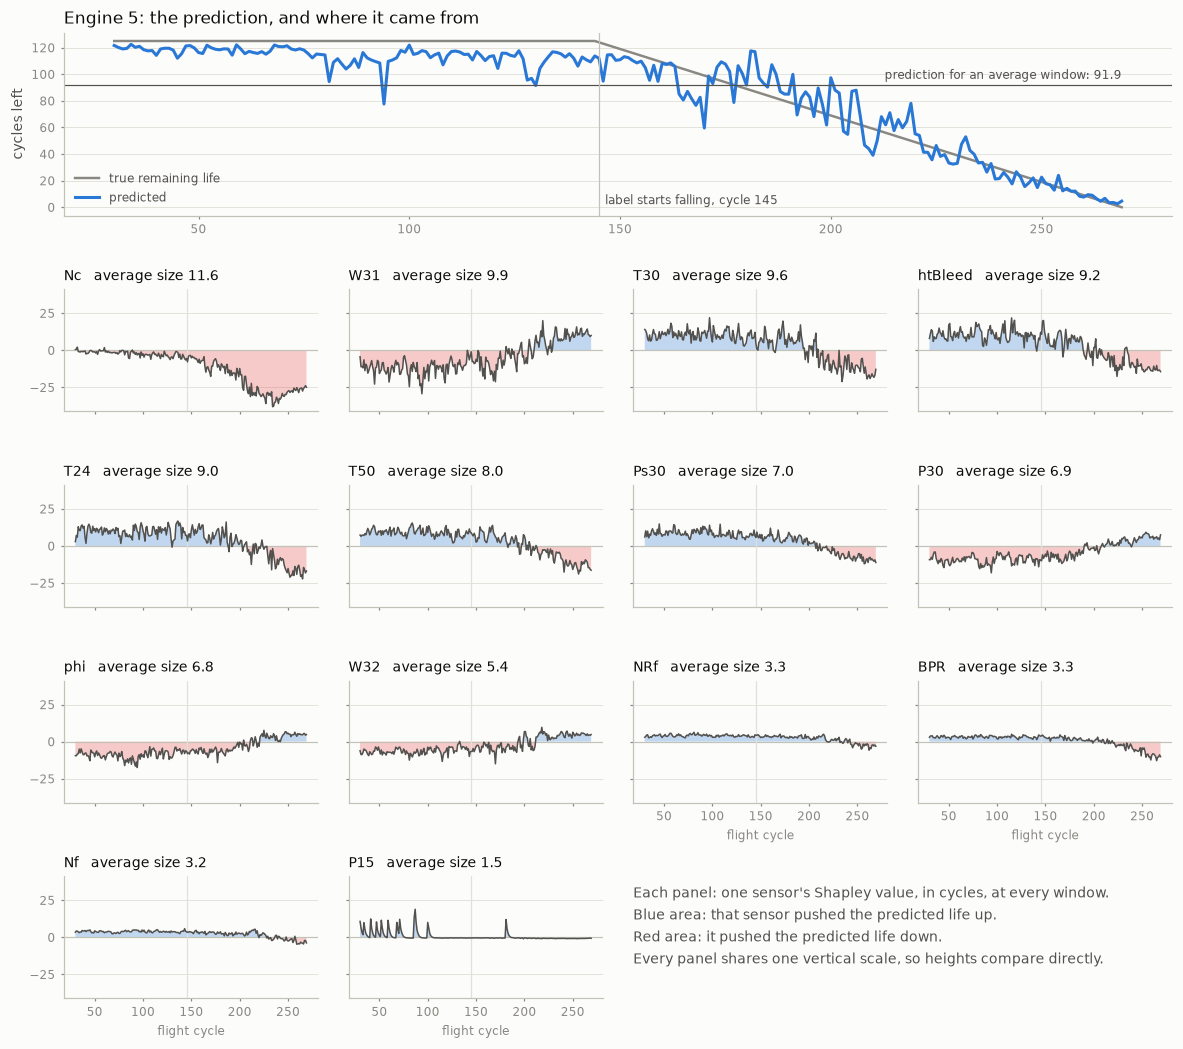

In [15]:
figure = plot_contributions_over_time(
    attribution, sensors, title=f"Engine {engine}: the prediction, and where it came from"
)
plt.show()

#### Reading the figure

**While the engine is healthy, many sensors contribute and they pull in opposite directions.** `T30`, `htBleed`, `T24`, `T50` and `Ps30` push the prediction up, while `W31`, `P30`, `phi` and `W32` push it down, each by amounts of the same order. The prediction sits well above the reference because the pushes up outweigh the pushes down. Remember what "up" is measured against: the stand-in is the average training window, and the training windows include worn engines. A healthy engine's perfectly normal readings therefore count as "better than typical", and that is what the blue areas record.

**As the engine wears, the picture reorganises around one sensor.** `Nc`, the core speed, contributes almost nothing for the first half of the engine's life and then becomes by far the largest single contribution, pulling the prediction down. At the same time, the sensors that pushed up while the engine was healthy cross zero and push down, and several that pushed down cross to pushing up. Step 6 puts numbers on both movements.

**`P15` is nearly silent**, apart from narrow spikes early in the engine's life. It takes only two distinct values in the whole FD001 training set, so its readings change only when it flips from one to the other (finding F-01).

### Step 6 — Which sensors mattered, overall and by stage of life

**What.** Two summaries of step 5's table.

- **Overall**, from `shap_summary`: each sensor's average contribution size ignoring direction (`mean_abs`), its average signed contribution (`mean`, where a negative value means it pulled the prediction down on average), and the largest single contribution it made (`max_abs`).
- **By stage**: the average size of each sensor's contribution in the first, middle and last third of the engine's windows.

**Why.** The figure shows the shapes; these tables put numbers to them, and the stage table measures the change over the engine's life that the paper's dynamic explanation is about. The paper's Table 12 picks five consecutive moments at each of three stages of one engine. Thirds of this engine's life are used here instead, because this engine has a different length, and because averaging over a whole third is steadier than five moments.

In [16]:
ranking = shap_summary(attribution[sensors].to_numpy(), sensors)
print(f"Engine {engine}, all {len(attribution)} windows, sorted by average size:")
display(ranking.round(2))

thirds = np.array_split(np.arange(len(attribution)), 3)
stages = pd.DataFrame({
    f"{name} third (cycles {attribution['end_cycle'].iloc[rows[0]]}-{attribution['end_cycle'].iloc[rows[-1]]})":
        attribution[sensors].iloc[rows].abs().mean()
    for name, rows in zip(("first", "middle", "last"), thirds)
})
stages["last minus first"] = stages.iloc[:, 2] - stages.iloc[:, 0]
print("Average size of each sensor's contribution, by third of the engine's life:")
display(stages.sort_values(stages.columns[2], ascending=False).round(2))

Engine 5, all 240 windows, sorted by average size:


,sensor,mean_abs,mean,max_abs
0,Nc,11.62,-11.57,38.05
1,W31,9.91,-5.29,29.34
2,T30,9.57,3.74,21.96
3,htBleed,9.20,3.85,21.84
4,T24,9.02,3.75,22.20
5,T50,8.01,3.29,18.89
6,Ps30,6.97,3.78,14.83
7,P30,6.93,-4.90,18.13
8,phi,6.75,-4.99,17.44
9,W32,5.37,-2.94,14.95


Average size of each sensor's contribution, by third of the engine's life:


,first third (cycles 30-109),middle third (cycles 110-189),last third (cycles 190-269),last minus first
Nc,1.67,6.63,26.55,24.88
T30,10.73,8.32,9.67,-1.06
T24,9.57,8.88,8.61,-0.97
htBleed,10.73,8.63,8.22,-2.51
W31,12.73,9.03,7.98,-4.75
T50,9.52,6.91,7.60,-1.92
Ps30,9.00,6.38,5.54,-3.45
W32,6.83,4.89,4.39,-2.44
BPR,3.18,2.67,4.00,0.83
phi,9.54,7.04,3.68,-5.86


In the stage table, `Nc` goes from the smallest contribution of all fourteen in the first third to by far the largest in the last, and the last column shows it gaining more than any other sensor. `P30`, `phi` and `W31` lose the most. Near failure, then, this network's prediction rests largely on one sensor, where earlier it rested on many small pushes that partly cancelled.

**Check.** `P15` carries almost no information (finding F-01), so a sensible attribution should rank it last overall. It is not a proof that the attribution is right, but a ranking that put `P15` near the top would be a warning.

In [17]:
p15_rank = int(ranking.index[ranking["sensor"] == "P15"][0]) + 1
p15_last = p15_rank == len(sensors)
assert p15_last
print(f"OK  P15 ranks {p15_rank} of {len(sensors)} for engine {engine}.")

late_leader = stages.iloc[:, 2].idxmax()
print(f"Largest average contribution in the last third: {late_leader}")

OK  P15 ranks 14 of 14 for engine 5.
Largest average contribution in the last third: Nc


## 5. Is the ranking a property of the architecture, or of one network?

### Step 7 — The other four networks

**What.** Load each of the run's five networks, compute Shapley values for the last window of each of the 100 test engines, and rank the sensors by average contribution size for each network. Then measure how closely the five rankings agree.

**Why.** Everything above describes seed 42's network. The other four seeds trained networks of the same design on slightly different data (each held back different engines) from different starting values. A ranking that changes when only the seed changes describes that one network, not the design. The test engines are used here because they are the same 100 for every network, while the held-back engines differ from seed to seed. Explaining them decides nothing about any network, so it does not use up the test set.

**How agreement is measured.** Spearman's rank correlation compares two rankings: 1 means the same order, 0 no relationship, −1 the reverse order. With no ties it is `1 − 6 × Σd² / (m × (m² − 1))`, where `m` is the number of items ranked and `d` is how far apart one item's two ranks are. For three items ranked `[1, 2, 3]` by one network and `[1, 3, 2]` by another, the differences are `0, −1, 1`, so `Σd² = 2` and the correlation is `1 − 6 × 2 / (3 × 8) = 0.5`. Here `m = 14` sensors.

In [18]:
sizes = {}
for seed in run.seeds:
    network, data = load_seed(run, seed)
    started = time.perf_counter()
    values = shap_values(network, data.test.features, mean_window_baseline(data.train))
    sizes[seed] = pd.Series(np.abs(values).mean(axis=0), index=sensors)
    print(f"seed {seed}: {len(data.test)} test windows in {time.perf_counter() - started:.1f} s; "
          f"largest four {sizes[seed].sort_values(ascending=False).index[:4].tolist()}")

sizes = pd.DataFrame(sizes)
ranks = sizes.rank(ascending=False).astype(int)
print("\nRank of each sensor by average contribution size, one column per network:")
display(ranks.sort_values(SEED))

agreement = sizes.corr(method="spearman")
off_diagonal = agreement.to_numpy()[~np.eye(len(agreement), dtype=bool)]
print("Spearman's rank correlation between every pair of networks:")
display(agreement.round(2))
print(f"lowest {off_diagonal.min():.2f}, highest {off_diagonal.max():.2f}")

seed 42: 100 test windows in 5.6 s; largest four ['Nc', 'T24', 'W31', 'T30']


seed 43: 100 test windows in 5.8 s; largest four ['Nc', 'T24', 'W31', 'T50']


seed 44: 100 test windows in 6.0 s; largest four ['T24', 'Nc', 'T30', 'W31']


seed 45: 100 test windows in 8.3 s; largest four ['Nc', 'T24', 'W31', 'T30']


seed 46: 100 test windows in 7.8 s; largest four ['T24', 'Nc', 'W31', 'T50']

Rank of each sensor by average contribution size, one column per network:


,42,43,44,45,46
Nc,1,1,2,1,2
T24,2,2,1,2,1
W31,3,3,4,3,3
T30,4,5,3,4,5
T50,5,4,12,6,4
htBleed,6,6,7,5,6
Nf,7,7,5,7,7
NRf,8,8,6,9,8
Ps30,9,9,8,8,9
BPR,10,10,10,11,10


Spearman's rank correlation between every pair of networks:


,42,43,44,45,46
42,1.00,1.00,0.85,0.99,0.99
43,1.00,1.00,0.81,0.98,1.00
44,0.85,0.81,1.00,0.87,0.82
45,0.99,0.98,0.87,1.00,0.97
46,0.99,1.00,0.82,0.97,1.00


lowest 0.81, highest 1.00


**Check.** Two statements this notebook relies on must hold for every one of the five networks, not only seed 42's: `P15` is ranked last, and `Nc` and `T24` are the two sensors with the largest average contributions.

In [19]:
p15_last_everywhere = bool((ranks.loc["P15"] == len(sensors)).all())
top_two_everywhere = all(
    set(sizes[seed].sort_values(ascending=False).index[:2]) == {"Nc", "T24"}
    for seed in run.seeds
)
assert p15_last_everywhere
assert top_two_everywhere
print("OK  Every network ranks P15 last.")
print("OK  Every network's two largest average contributions are Nc and T24, in one order or the other.")

OK  Every network ranks P15 last.
OK  Every network's two largest average contributions are Nc and T24, in one order or the other.


The rankings agree closely, and the two statements hold for all five networks. So, for this design and these test engines, which sensors carry the largest contributions is not an accident of one seed. The correlation table shows one network, seed 44, agreeing a little less with the others than they do with each other, mostly because it ranks `T50` twelfth where the other four rank it between fourth and sixth.

## 6. What a Shapley value does and does not show

1. **What object is explained?** One prediction: one window in, one number of cycles out. Step 5's picture is many such explanations side by side, not an explanation of the network as a whole.
2. **What does the method have access to?** Only the network's inputs and outputs. It never reads a parameter or a gradient; it runs the network as a function, 16,384 times per window. So it could explain any model that takes these inputs.
3. **What does it change?** Whole sensors. A sensor's 30 readings are kept or replaced together, never cycle by cycle, so it cannot say which cycles inside the window mattered. It never changes the sensor graph either.
4. **What does it measure?** How far the prediction moves when a sensor joins a group of the others, averaged over every group with the weights of Equation 15.
5. **What is the result?** Fourteen signed numbers per window, in cycles, adding up to the prediction minus the reference prediction.
6. **What does it assume?**
   - That "absent" is best represented by the sensor's average training window (assumption A-20). A different stand-in gives different values.
   - That the network's answers for windows mixing real and average readings mean something, although no real engine ever produced such a window.
   - That credit for an interaction between sensors should be split evenly among them.
7. **What does it not show?**
   - **Cause.** `Nc` having the largest contributions near failure says this network's prediction moved most with `Nc`'s readings. It does not say the core speed causes wear, or that it is physically the best sign of wear.
   - **That the prediction was right.** A wrong prediction is split up just as neatly, and the values add up even for a network that was never trained, because efficiency is a property of the arithmetic.
   - **Which connections carried the information.** Credit goes to sensors, not to the edges of the sensor graph between them. Which edges a prediction depended on is a different question, and the one this thesis goes on to ask.
   - **Anything about another design.** Step 7 compares five networks of one design. A network with the paper's recurrent stage, or a different sensor graph, would need its own explanation.

**Do not confuse** "`Nc` has the largest Shapley values near failure" with "`Nc` is the most important measurement of engine wear". The first is measured above. The second would need evidence about engines, not about one network.

## 7. Final verification

Every check of this notebook, in one place. A reader who trusts nothing else should be able to run this cell.

In [20]:
checks = [
    ("The loaded network scores what the run recorded", same_network, f"seed {SEED}"),
    ("The reference prediction is a possible prediction", reference_in_range, f"{reference:.2f} cycles"),
    ("Three sensors: the values add up", three_add_up, "step 3"),
    ("Three sensors: orders and groups agree", routes_agree, "Equation 15's weights"),
    ("Fourteen sensors: the values add up", fourteen_add_up, f"{window_error:.1e} cycles"),
    (f"Every window of engine {engine} adds up", every_window_adds_up,
     f"{engine_gap:.1e} cycles over {len(attribution)} windows"),
    ("P15 is ranked last for this engine", p15_last, f"rank {p15_rank}"),
    ("P15 is ranked last by all five networks", p15_last_everywhere, "100 test engines"),
    ("Nc and T24 lead for all five networks", top_two_everywhere, "100 test engines"),
]
width = max(len(name) for name, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 40))
for name, passed, detail in checks:
    print(f"{name:<{width}} {'PASS' if passed else 'FAIL':<8} {detail}")
print("-" * (width + 40))
failed = [name for name, passed, _ in checks if not passed]
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks)} checks passed.")

CHECK                                               RESULT   DETAIL
-------------------------------------------------------------------------------------------
The loaded network scores what the run recorded     PASS     seed 42
The reference prediction is a possible prediction   PASS     91.89 cycles
Three sensors: the values add up                    PASS     step 3
Three sensors: orders and groups agree              PASS     Equation 15's weights
Fourteen sensors: the values add up                 PASS     9.5e-07 cycles
Every window of engine 5 adds up                    PASS     4.8e-07 cycles over 240 windows
P15 is ranked last for this engine                  PASS     rank 14
P15 is ranked last by all five networks             PASS     100 test engines
Nc and T24 lead for all five networks               PASS     100 test engines
-------------------------------------------------------------------------------------------
All 9 checks passed.


## 8. Summary

### What this notebook produced

- **Seed 42's trained network, loaded from a stored run** and confirmed to be that run's network by its test error.
- **Shapley values worked by hand** for three sensors, over every order they could arrive in, and shown to equal the group-by-group form of Equation 15.
- **Exact Shapley values for all fourteen sensors**, for one window and then for every window of one held-back engine's life, adding up to the prediction minus the reference prediction at every window.
- **A chart of how each sensor's contribution moved over that engine's life**, and a table of the same by stage: many small, opposing contributions while the engine is healthy, reorganising around `Nc` as it nears failure.
- **A ranking that holds across all five of the run's networks**, with `P15` last and `Nc` and `T24` first.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| What stands in for a removed sensor | Its average window over the training engines | A-20 |
| What the fourteen values add up to | The prediction minus the prediction for the stand-in window, not the average label | A-24 |
| Which engine is followed over its life | The held-back engine with the most windows | this notebook |
| How stages of life are summarised | Thirds of the engine's windows | this notebook |

### What comes next

- **`02_occlusion_fd001.ipynb`** explains the same network with a cheaper method that is not in the paper, and shows where it agrees with the Shapley values and where it cannot.
- **Edges instead of sensors.** Every value here credits a sensor. Which connections of the sensor graph a prediction depended on is the question the paper does not ask and this thesis does.

### References

- Shapley, L. S. (1953). A value for n-person games. *Contributions to the Theory of Games II*, 307-317.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 30*.
- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement for aeroengine RUL prediction. *Aerospace Science and Technology*, 168, 110875.

Full citations are in `docs/REFERENCES.md`.